# YOLOv12n · Skenario Sintetis 100%

Notebook ini melatih dan mengevaluasi **YOLOv12 varian Nano** pada skenario **sintetis 100%**, yaitu 700 citra siang hari ditambah 700 citra malam sintetis CycleGAN-Turbo (100% dari jumlah citra latih asli), lalu diaugmentasi 3×. Notebook ini adalah satu dari 15 konfigurasi pelatihan pada naskah.

| Pengaturan | Nilai |
|---|---|
| Model awal | `yolov12n.pt` (pretrained COCO) |
| Dataset (Kaggle) | `pororozagi/aug-cycle` |
| Data latih / validasi / uji | 4.200 / 200 / 100 citra |
| Epoch | 50 |
| Ukuran citra | 640 × 640 |
| Batch | 16 |
| Optimizer | SGD (lr0 = 0,01, momentum = 0,937, weight decay = 0,0005) |
| Nama run | `yolov12n_sintetis100` |

**Hasil pada data uji** (100 citra malam NPD, 166 objek), sesuai naskah:

| Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---|---|---|
| 0,6132* | 0,5843* | 0,5867* | 0,2976* |

Seluruh bobot, kurva, dan ringkasan metrik disimpan ke Google Drive pada folder `MyDrive/Output Yolo/100 Sintetis/yolov12n_sintetis100`.

\* Angka diambil dari naskah. Output notebook ini hilang sehingga perlu dijalankan ulang untuk memperoleh hasilnya kembali.

## 1. Cek GPU

Pelatihan dijalankan pada GPU Tesla T4 di Google Colab. Pastikan runtime sudah diatur ke GPU melalui **Runtime → Change runtime type → T4 GPU**.

In [1]:
!nvidia-smi

Fri Oct 23 09:23:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Kunci versi PyTorch

Versi PyTorch bawaan Colab dapat berubah sewaktu-waktu. Sel berikut memasang torch 2.9.0 agar lingkungan sama dengan seluruh eksperimen. Setelah instalasi, runtime perlu dimulai ulang supaya versi baru termuat.

> Jalankan dua sel di bawah ini **satu kali**. Pesan *"Your session crashed"* setelah sel kedua adalah hal yang wajar. Setelah itu, lanjutkan dari bagian **3. Instal dependensi** (jangan menggunakan *Run all* dari atas).

In [2]:
!pip install -q torch==2.9.0 torchvision==0.24.0 torchaudio==2.9.0 --index-url https://download.pytorch.org/whl/cu128

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 163.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 210.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 199.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 61.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 35.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 95.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 40.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 95.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.2/288.2 MB 70.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.2/287.2 MB 96.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.3/322.3 MB 77.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.7/124.7 MB 79.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
# Mulai ulang runtime agar torch 2.9.0 termuat
import os
os.kill(os.getpid(), 9)

## 3. Instal dependensi

YOLOv12 belum tersedia sebagai paket PyPI resmi, sehingga dipasang langsung dari repositori GitHub `sunsmarterjie/yolov12`. Repositori ini merupakan fork Ultralytics 8.3.63. Instalasi dikunci ke commit `3bca22b` agar kode pelatihan, augmentasi bawaan, dan fungsi loss identik dengan yang dipakai pada seluruh eksperimen.

FlashAttention tidak dipasang karena tidak didukung oleh GPU T4. Pada GPU ini, YOLOv12 otomatis memakai *scaled dot-product attention*.

Sel kedua memeriksa versi lingkungan dan akan berhenti dengan pesan kesalahan bila ada versi yang tidak sesuai.

In [1]:
!pip install -q "git+https://github.com/sunsmarterjie/yolov12.git@3bca22b336e96cfdabfec4c062b84eef210e9563"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import sys, torch, ultralytics

print("Python      :", sys.version.split()[0])
print("Torch       :", torch.__version__, "| CUDA:", torch.version.cuda)
print("Ultralytics :", ultralytics.__version__)
print("GPU         :", torch.cuda.get_device_name(0))

assert torch.__version__.startswith("2.9.0"), f"Versi torch tidak sesuai: {torch.__version__}"
assert ultralytics.__version__ == "8.3.63",   f"Versi Ultralytics tidak sesuai: {ultralytics.__version__}"
assert "T4" in torch.cuda.get_device_name(0), f"GPU bukan T4: {torch.cuda.get_device_name(0)}"

print("\nLingkungan sesuai dengan konfigurasi eksperimen.")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/yolov12/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
FlashAttention is not available on this device. Using scaled_dot_product_attention instead.
Python      : 3.13.15
Torch       : 2.9.0+cu128 | CUDA: 12.8
Ultralytics : 8.3.63
GPU         : Tesla T4

Lingkungan sesuai dengan konfigurasi eksperimen.


## 4. Konfigurasi eksperimen

Seluruh nama yang berbeda antar-notebook dikumpulkan di sel ini. Sel lain tidak perlu diubah.

In [3]:
MODEL_WEIGHTS = "yolov12n.pt"                    # varian YOLOv12
DATASET_SLUG  = "pororozagi/aug-cycle"    # skenario data latih (Kaggle)
SCENARIO      = "Sintetis 100% (700 citra siang + 700 citra malam sintetis, augmentasi 3x)"
RUN_NAME      = "yolov12n_sintetis100"    # nama folder hasil pelatihan

EXPORT_PATH   = "/content/dataset"
DATA_YAML     = "/content/data_ready.yaml"

# Lokasi penyimpanan hasil di Google Drive
OUTPUT_GROUP  = "100 Sintetis"            # Baseline / 50 Sintetis / 100 Sintetis / SOTA
OUTPUT_DIR    = f"/content/drive/MyDrive/Output Yolo/{OUTPUT_GROUP}/{RUN_NAME}"

## 5. Unduh dataset dari Kaggle

Dataset diunduh dari Kaggle menggunakan kredensial yang disimpan di **Colab Secrets** (`KAGGLE_USERNAME` dan `KAGGLE_KEY`). Setelah diekstrak, path pada `data.yaml` ditulis ulang menjadi path absolut, lalu jumlah citra dan label pada setiap split diperiksa.

In [6]:
import os
import yaml
from google.colab import userdata

# 1. Kredensial Kaggle dari Colab Secrets
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

# 2. Unduh dan ekstrak dataset
if not os.path.exists(EXPORT_PATH):
    print("⏳ Sedang mendownload dataset...")
    !kaggle datasets download -d {DATASET_SLUG} -p {EXPORT_PATH} --unzip
    print("✅ Download selesai.")
else:
    print("ℹ️ Dataset sudah ada.")

# 3. Cari folder root dataset (yang berisi train dan valid)
actual_base_path = EXPORT_PATH
for root, dirs, files in os.walk(EXPORT_PATH):
    if 'train' in dirs and 'valid' in dirs:
        actual_base_path = root
        break
print(f"📍 Root dataset ditemukan di: {actual_base_path}")

# 4. Tulis ulang data.yaml dengan path absolut
yaml_src = None
for root, dirs, files in os.walk(EXPORT_PATH):
    for f in files:
        if f.endswith('.yaml'):
            yaml_src = os.path.join(root, f)
            break

if yaml_src:
    with open(yaml_src, 'r') as f:
        data = yaml.safe_load(f)

    data['train'] = os.path.join(actual_base_path, 'train', 'images')
    data['val']   = os.path.join(actual_base_path, 'valid', 'images')
    data['test']  = os.path.join(actual_base_path, 'test', 'images')

    with open(DATA_YAML, 'w') as f:
        yaml.dump(data, f)
    print(f"✅ YAML diperbaiki: {DATA_YAML}")
else:
    print("❌ ERROR: File .yaml tidak ditemukan!")

# 5. Periksa jumlah citra dan label pada setiap split
print("\n" + "="*30)
print("📊 LAPORAN DATASET")
print("="*30)

for split in ['train', 'valid', 'test']:
    img_dir = os.path.join(actual_base_path, split, 'images')
    lbl_dir = os.path.join(actual_base_path, split, 'labels')

    if os.path.exists(img_dir) and os.path.exists(lbl_dir):
        n_imgs = len([f for f in os.listdir(img_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
        n_lbls = len([f for f in os.listdir(lbl_dir) if f.endswith('.txt')])

        status = "✅ MATCH" if n_imgs == n_lbls else "❌ MISMATCH"
        print(f"[{split.upper()}]")
        print(f"  - Gambar: {n_imgs}")
        print(f"  - Label : {n_lbls}")
        print(f"  - Status: {status}")

        if n_imgs == 0:
            print(f"  ⚠️ PERINGATAN: Folder {split} kosong!")
    else:
        print(f"❌ [{split.upper()}] Folder images/labels tidak ditemukan!")

print("="*30)

⏳ Sedang mendownload dataset...
Dataset URL: https://www.kaggle.com/datasets/pororozagi/aug-cycle
License(s): unknown
100% 313M/313M [00:09<00:00, 36.4MB/s]

✅ Download selesai.
📍 Root dataset ditemukan di: /content/dataset/The aug
✅ YAML diperbaiki: /content/data_ready.yaml

📊 LAPORAN DATASET
[TRAIN]
  - Gambar: 4200
  - Label : 4200
  - Status: ✅ MATCH
[VALID]
  - Gambar: 200
  - Label : 200
  - Status: ✅ MATCH
[TEST]
  - Gambar: 100
  - Label : 100
  - Status: ✅ MATCH


**Catatan.** Output notebook ini hilang (notebook tidak sengaja dimuat ulang), sehingga belum ada hasil yang dapat dibahas di sini. Bagian ini akan berisi insight setelah notebook dijalankan ulang.

## 6. Pelatihan model

Model diinisialisasi dari bobot pretrained COCO, lalu di-*fine-tune* selama 50 epoch. Hyperparameter pada sel ini sama untuk seluruh 15 konfigurasi (tabel hyperparameter pelatihan di Bab 4 naskah), sedangkan hyperparameter lain mengikuti nilai bawaan Ultralytics, termasuk `seed=0`. Bobot dengan nilai *fitness* validasi tertinggi disimpan sebagai `best.pt`.

In [7]:
from ultralytics import YOLO
import torch
import os

# 1. Cek perangkat
device_to_use = 0 if torch.cuda.is_available() else 'cpu'
if device_to_use == 'cpu':
    print("⚠️ PERINGATAN: GPU tidak terdeteksi. Training akan sangat lambat!")
else:
    print(f"✅ GPU Terdeteksi: {torch.cuda.get_device_name(0)}")

# 2. Muat bobot pretrained COCO sebagai titik awal fine-tuning
model = YOLO(MODEL_WEIGHTS)

# 3. Pelatihan
assert os.path.exists(DATA_YAML), f"{DATA_YAML} tidak ditemukan. Jalankan sel unduh dataset terlebih dahulu."

results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=16,
    optimizer='SGD',
    lr0=0.01,
    momentum=0.937,
    weight_decay=0.0005,
    device=device_to_use,
    name=RUN_NAME
)

✅ GPU Terdeteksi: Tesla T4
New https://pypi.org/project/ultralytics/8.4.184 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.63 🚀 Python-3.13.15 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: task=detect, mode=train, model=yolov12n.pt, data=/content/data_ready.yaml, epochs=50, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=None, name=yolov12n_sintetis100, exist_ok=False, pretrained=True, optimizer=SGD, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False

100%|██████████| 755k/755k [00:00<00:00, 45.5MB/s]


Overriding model.yaml nc=80 with nc=1

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      2368  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2, 1, 2]          
  2                  -1  1      6640  ultralytics.nn.modules.block.C3k2            [32, 64, 1, False, 0.25]      
  3                  -1  1      9344  ultralytics.nn.modules.conv.Conv             [64, 64, 3, 2, 1, 4]          
  4                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  5                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  6                  -1  2    174720  ultralytics.nn.modules.block.A2C2f           [128, 128, 2, True, 4]        
  7                  -1  1    295424  ultralytics

train: Scanning /content/dataset/The aug/train/labels... 4200 images, 0 backgrounds, 0 corrupt: 100%|██████████| 4200/4200 [00:02<00:00, 2048.17it/s]


train: New cache created: /content/dataset/The aug/train/labels.cache
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


...

      50/50      3.68G     0.9128     0.5628      1.186         15        640: 100%|██████████| 263/263 [01:22<00:00,  3.21it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 7/7 [00:01<00:00,  3.59it/s]

                   all        200        409      0.754      0.561      0.604      0.326



50 epochs completed in 1.231 hours.
Optimizer stripped from runs/detect/yolov12n_sintetis100/weights/last.pt, 5.4MB
Optimizer stripped from runs/detect/yolov12n_sintetis100/weights/best.pt, 5.4MB

Validating runs/detect/yolov12n_sintetis100/weights/best.pt...
Ultralytics 8.3.63 🚀 Python-3.13.15 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 376 layers, 2,508,539 parameters, 0 gradients, 5.8 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 7/7 [00:04<00:00,  1.73it/s]


                   all        200        409      0.717      0.616      0.669      0.347
Speed: 0.3ms preprocess, 7.3ms inference, 0.0ms loss, 4.3ms postprocess per image
Results saved to runs/detect/yolov12n_sintetis100


**Catatan.** Output notebook ini hilang (notebook tidak sengaja dimuat ulang), sehingga belum ada hasil yang dapat dibahas di sini. Bagian ini akan berisi insight setelah notebook dijalankan ulang.

## 7. Kurva pelatihan dan validasi

In [8]:
import os
import glob
import matplotlib.pyplot as plt
import cv2

results_dir = f'runs/detect/{RUN_NAME}'
if not os.path.exists(results_dir):
    # Gunakan folder run terbaru bila nama di atas tidak ditemukan
    results_dir = max(glob.glob('runs/detect/*'), key=os.path.getmtime)

print(f"📂 Mengambil hasil dari: {results_dir}")

📂 Mengambil hasil dari: runs/detect/yolov12n_sintetis100


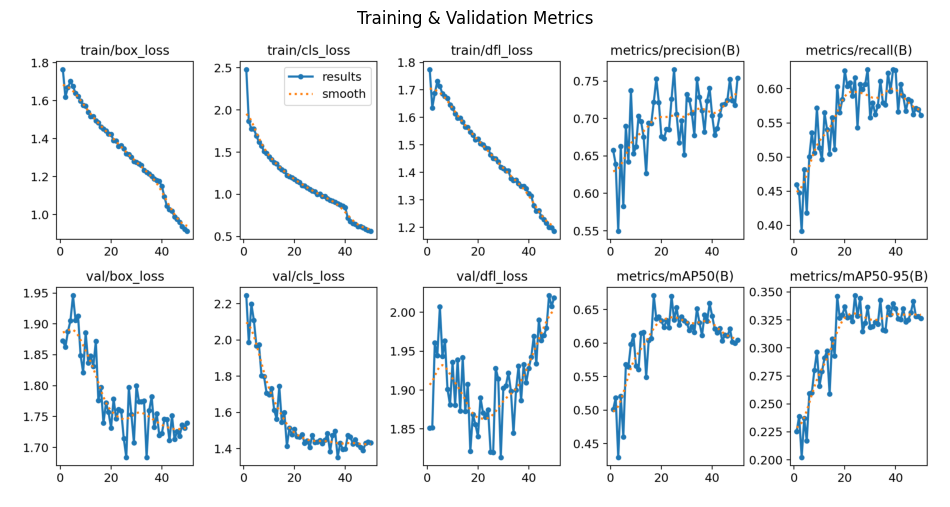

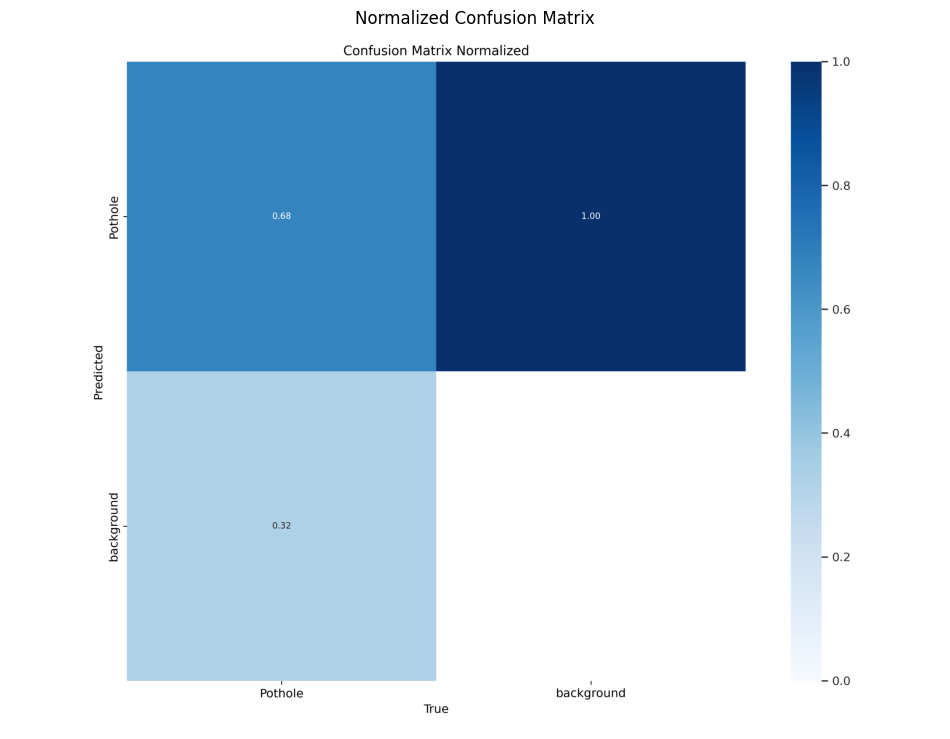

In [9]:
def show_image(path, title):
    if os.path.exists(path):
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(12, 10))
        plt.imshow(img)
        plt.title(title)
        plt.axis('off')
        plt.show()
    else:
        print(f"⚠️ File {path} tidak ditemukan.")

# Grafik loss dan metrik per epoch
show_image(f"{results_dir}/results.png", "Training & Validation Metrics")

# Confusion matrix ternormalisasi pada data validasi
show_image(f"{results_dir}/confusion_matrix_normalized.png", "Normalized Confusion Matrix")

**Catatan.** Output notebook ini hilang (notebook tidak sengaja dimuat ulang), sehingga belum ada hasil yang dapat dibahas di sini. Bagian ini akan berisi insight setelah notebook dijalankan ulang.

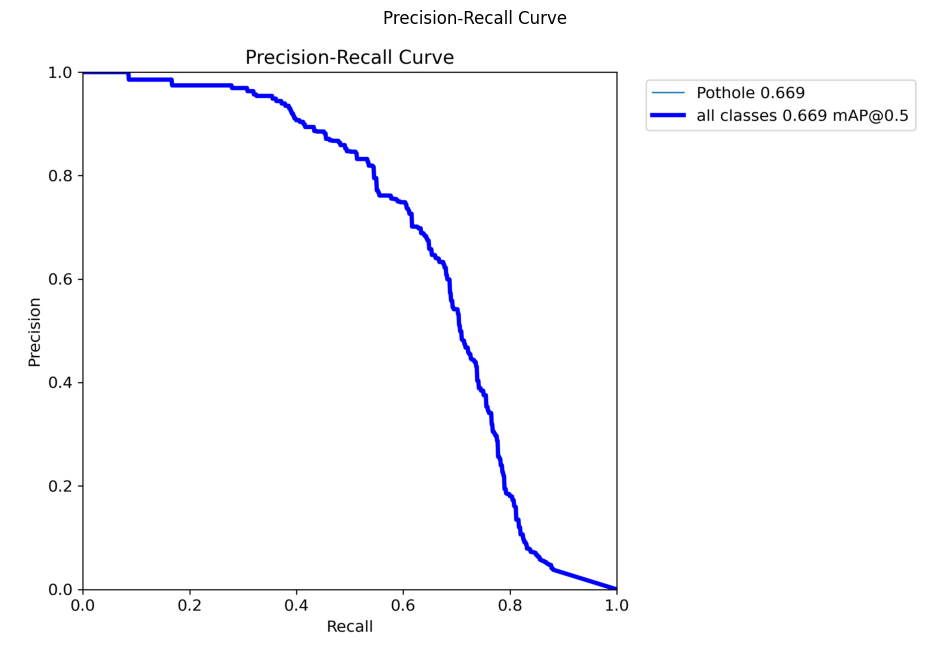

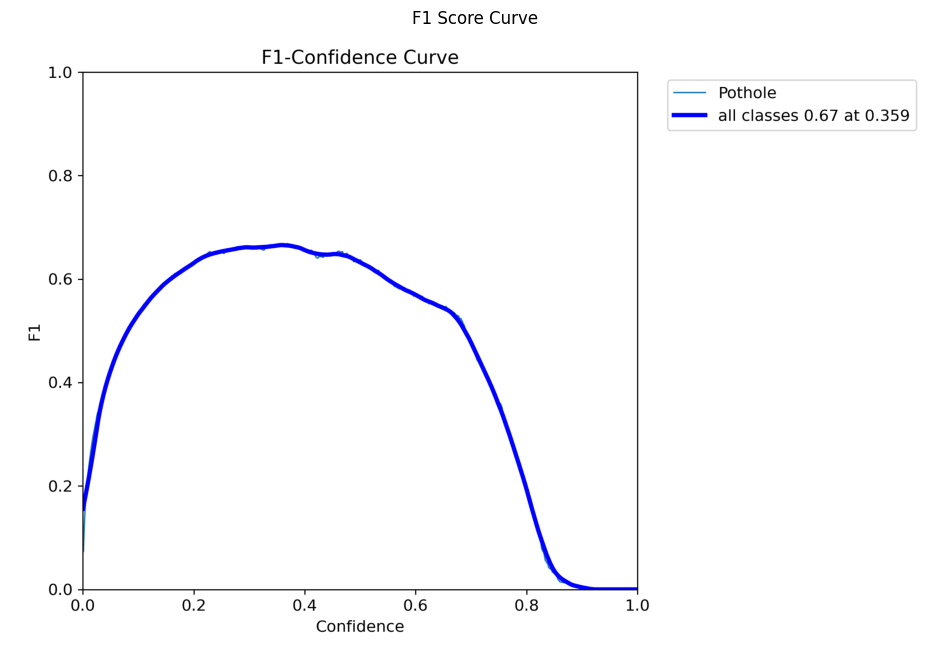

In [10]:
# Kurva Precision-Recall dan F1-confidence pada data validasi
show_image(f"{results_dir}/PR_curve.png", "Precision-Recall Curve")
show_image(f"{results_dir}/F1_curve.png", "F1 Score Curve")

**Catatan.** Output notebook ini hilang (notebook tidak sengaja dimuat ulang), sehingga belum ada hasil yang dapat dibahas di sini. Bagian ini akan berisi insight setelah notebook dijalankan ulang.

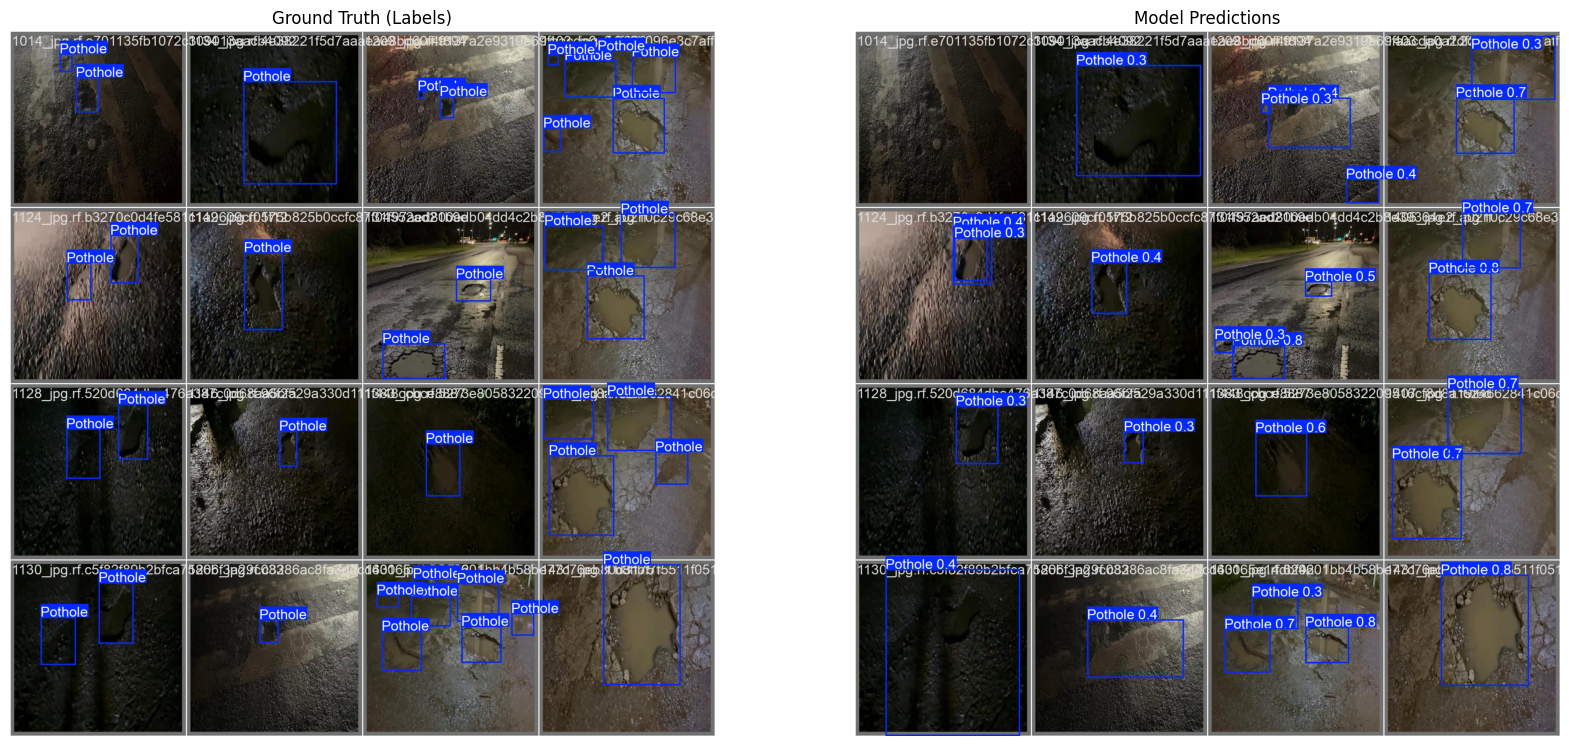

In [11]:
# Perbandingan label asli dan prediksi pada batch pertama data validasi
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

img_labels = cv2.imread(f"{results_dir}/val_batch0_labels.jpg")
axes[0].imshow(cv2.cvtColor(img_labels, cv2.COLOR_BGR2RGB))
axes[0].set_title("Ground Truth (Labels)")
axes[0].axis('off')

img_pred = cv2.imread(f"{results_dir}/val_batch0_pred.jpg")
axes[1].imshow(cv2.cvtColor(img_pred, cv2.COLOR_BGR2RGB))
axes[1].set_title("Model Predictions")
axes[1].axis('off')

plt.show()

### Kurva per epoch dari `results.csv`

Grafik bawaan Ultralytics digambar ulang dari `results.csv` agar loss latih dan loss validasi berada pada satu panel untuk setiap komponen, serta epoch terbaik ditandai secara eksplisit. Epoch terbaik ditentukan dengan nilai *fitness* yang sama dengan Ultralytics, yaitu 0,1 × mAP@0.5 + 0,9 × mAP@0.5:0.95.

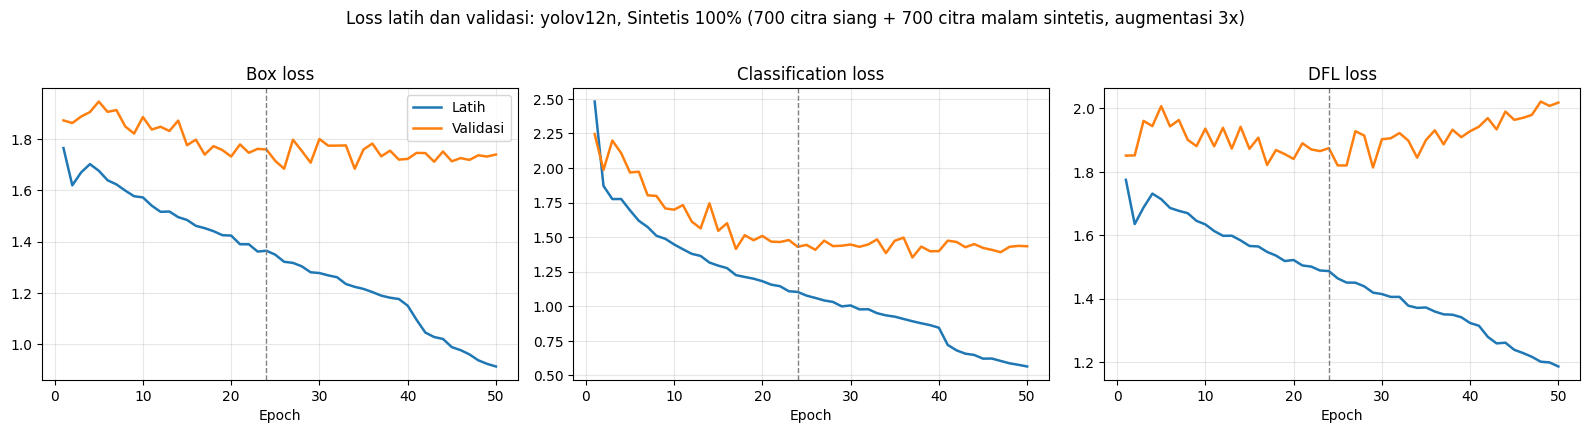

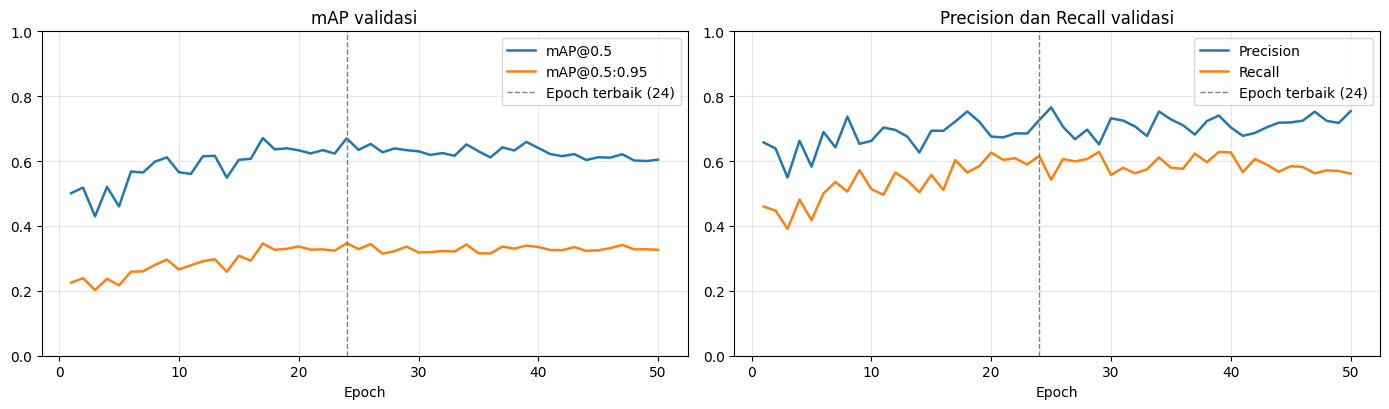

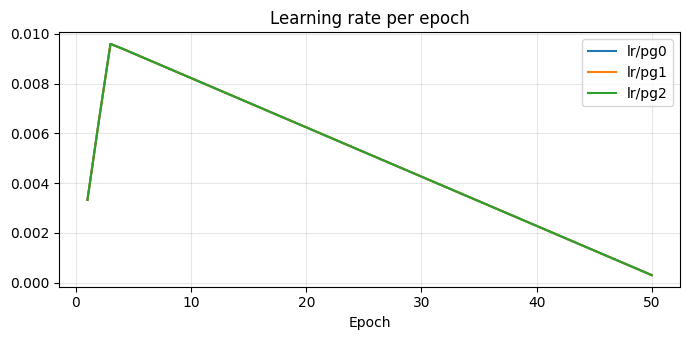

Epoch terbaik: 24
metrics/precision(B)    0.7260
metrics/recall(B)       0.6161
metrics/mAP50(B)        0.6700
metrics/mAP50-95(B)     0.3468


In [12]:
import pandas as pd

hist = pd.read_csv(f"{results_dir}/results.csv")
hist.columns = hist.columns.str.strip()
epochs = hist["epoch"]

fitness = 0.1 * hist["metrics/mAP50(B)"] + 0.9 * hist["metrics/mAP50-95(B)"]
best_idx = int(fitness.idxmax())
best_epoch = int(epochs[best_idx])

# Loss latih vs validasi
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, comp, title in zip(axes, ["box", "cls", "dfl"], ["Box loss", "Classification loss", "DFL loss"]):
    ax.plot(epochs, hist[f"train/{comp}_loss"], label="Latih", lw=1.8)
    ax.plot(epochs, hist[f"val/{comp}_loss"], label="Validasi", lw=1.8)
    ax.axvline(best_epoch, color="grey", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
axes[0].legend()
fig.suptitle(f"Loss latih dan validasi: {MODEL_WEIGHTS.replace('.pt', '')}, {SCENARIO}", y=1.02)
plt.tight_layout(); plt.show()

# Metrik validasi per epoch
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(epochs, hist["metrics/mAP50(B)"], label="mAP@0.5", lw=1.8)
axes[0].plot(epochs, hist["metrics/mAP50-95(B)"], label="mAP@0.5:0.95", lw=1.8)
axes[1].plot(epochs, hist["metrics/precision(B)"], label="Precision", lw=1.8)
axes[1].plot(epochs, hist["metrics/recall(B)"], label="Recall", lw=1.8)
for ax, title in zip(axes, ["mAP validasi", "Precision dan Recall validasi"]):
    ax.axvline(best_epoch, color="grey", ls="--", lw=1, label=f"Epoch terbaik ({best_epoch})")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

# Learning rate
lr_cols = [c for c in hist.columns if c.startswith("lr/")]
plt.figure(figsize=(7, 3.5))
for c in lr_cols:
    plt.plot(epochs, hist[c], label=c)
plt.title("Learning rate per epoch"); plt.xlabel("Epoch"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

print(f"Epoch terbaik: {best_epoch}")
print(hist.loc[best_idx, ["metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].round(4).to_string())

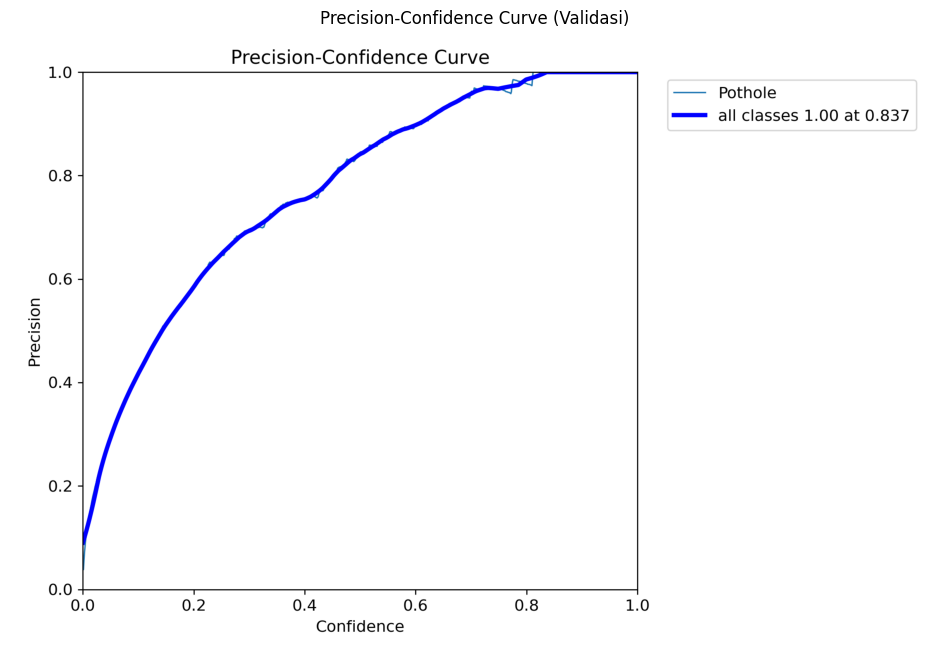

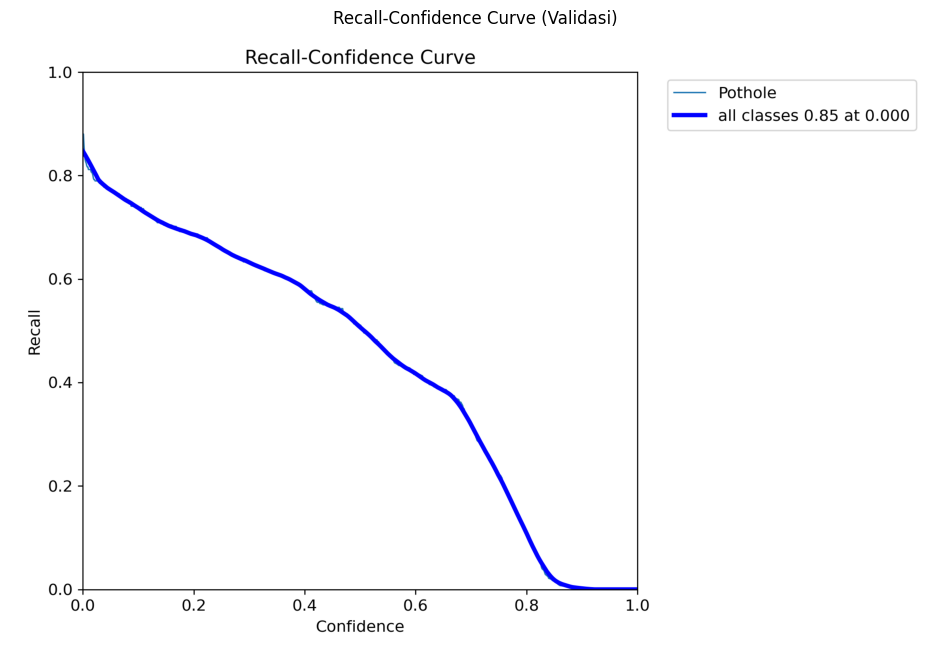

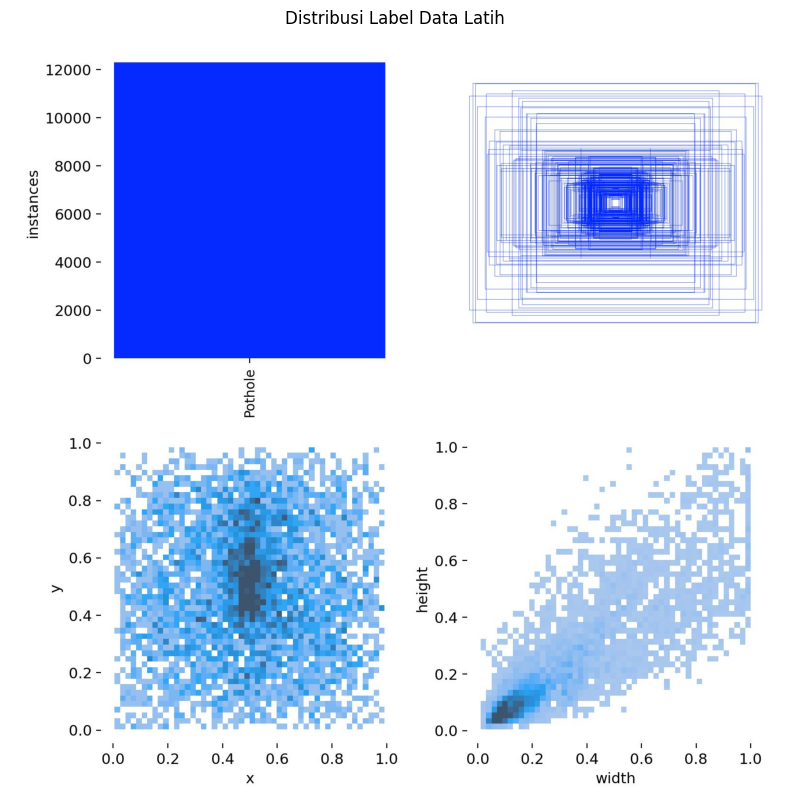

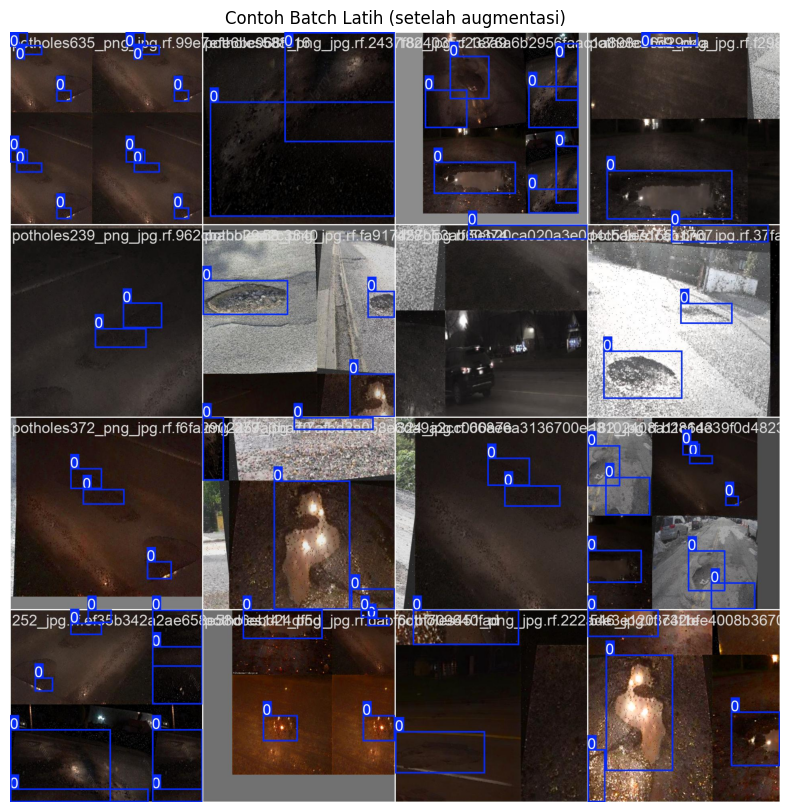

In [13]:
# Kurva Precision-confidence dan Recall-confidence pada data validasi
show_image(f"{results_dir}/P_curve.png", "Precision-Confidence Curve (Validasi)")
show_image(f"{results_dir}/R_curve.png", "Recall-Confidence Curve (Validasi)")

# Distribusi label pada data latih dan contoh batch latih setelah augmentasi
show_image(f"{results_dir}/labels.jpg", "Distribusi Label Data Latih")
show_image(f"{results_dir}/train_batch0.jpg", "Contoh Batch Latih (setelah augmentasi)")

## 8. Evaluasi pada data uji

Bobot terbaik (`best.pt`) dievaluasi pada split uji (100 citra malam NPD) dengan `split='test'`, `imgsz=640`, dan `batch=16`. mAP dihitung pada seluruh rentang confidence, sedangkan Precision dan Recall dilaporkan pada confidence yang menghasilkan F1 maksimum.

In [14]:
from ultralytics import YOLO
import os

best_model_path = f'runs/detect/{RUN_NAME}/weights/best.pt'
model = YOLO(best_model_path)

metrics = model.val(
    data=DATA_YAML,
    split='test',
    imgsz=640,
    batch=16,
    name=f'eval_test_{RUN_NAME}'
)

def get_metric(metrics_dict, keys):
    # Nama key berbeda antarversi Ultralytics
    for key in keys:
        if key in metrics_dict:
            return metrics_dict[key]
    return 0.0

res = metrics.results_dict
map50 = get_metric(res, ['metrics/map50', 'metrics/mAP50(B)'])
map95 = get_metric(res, ['metrics/map50-95', 'metrics/mAP50-95(B)'])
prec  = get_metric(res, ['metrics/precision', 'metrics/precision(B)'])
rec   = get_metric(res, ['metrics/recall', 'metrics/recall(B)'])

print("\n" + "="*30)
print("📈 HASIL EVALUASI DATA TEST")
print("="*30)
print(f"mAP50:       {map50:.4f}")
print(f"mAP50-95:    {map95:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"Recall:      {rec:.4f}")
print("="*30)

Ultralytics 8.3.63 🚀 Python-3.13.15 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 376 layers, 2,508,539 parameters, 0 gradients, 5.8 GFLOPs


val: Scanning /content/dataset/The aug/test/labels... 100 images, 0 backgrounds, 0 corrupt: 100%|██████████| 100/100 [00:00<00:00, 2043.91it/s]

val: New cache created: /content/dataset/The aug/test/labels.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 7/7 [00:02<00:00,  2.48it/s]


                   all        100        166      0.613      0.584      0.587      0.298
Speed: 0.3ms preprocess, 12.3ms inference, 0.0ms loss, 3.3ms postprocess per image
Results saved to runs/detect/eval_test_yolov12n_sintetis100

📈 HASIL EVALUASI DATA TEST
mAP50:       0.5867
mAP50-95:    0.2976
Precision:   0.6132
Recall:      0.5843


**Catatan.** Output notebook ini hilang (notebook tidak sengaja dimuat ulang), sehingga belum ada hasil yang dapat dibahas di sini. Bagian ini akan berisi insight setelah notebook dijalankan ulang.


0: 640x640 4 Potholes, 35.1ms
1: 640x640 2 Potholes, 35.1ms
2: 640x640 2 Potholes, 35.1ms
Speed: 2.0ms preprocess, 35.1ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)


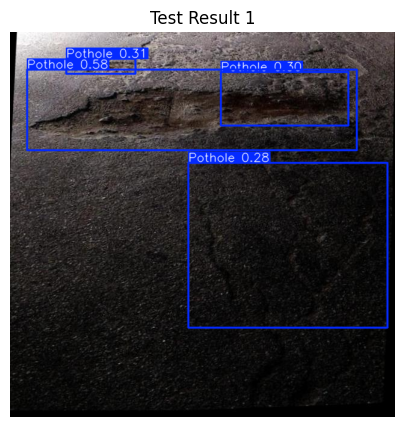

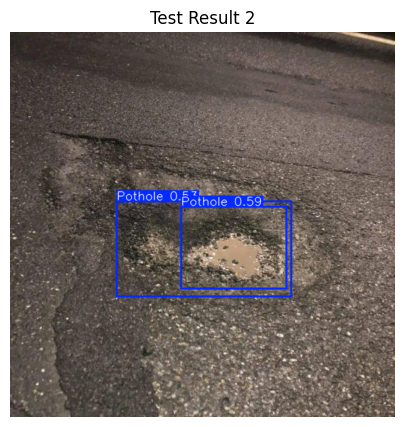

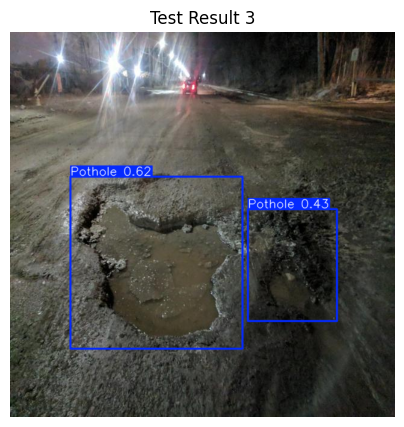

In [15]:
import glob
import yaml

# Contoh prediksi pada tiga citra pertama data uji (confidence 0,25)
with open(DATA_YAML, 'r') as f:
    config = yaml.safe_load(f)
test_files = glob.glob(os.path.join(config['test'], "*.jpg"))[:3]

results = model.predict(source=test_files, conf=0.25)

for i, r in enumerate(results):
    img_rgb = cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(5, 5))
    plt.imshow(img_rgb)
    plt.title(f"Test Result {i+1}")
    plt.axis('off')
    plt.show()

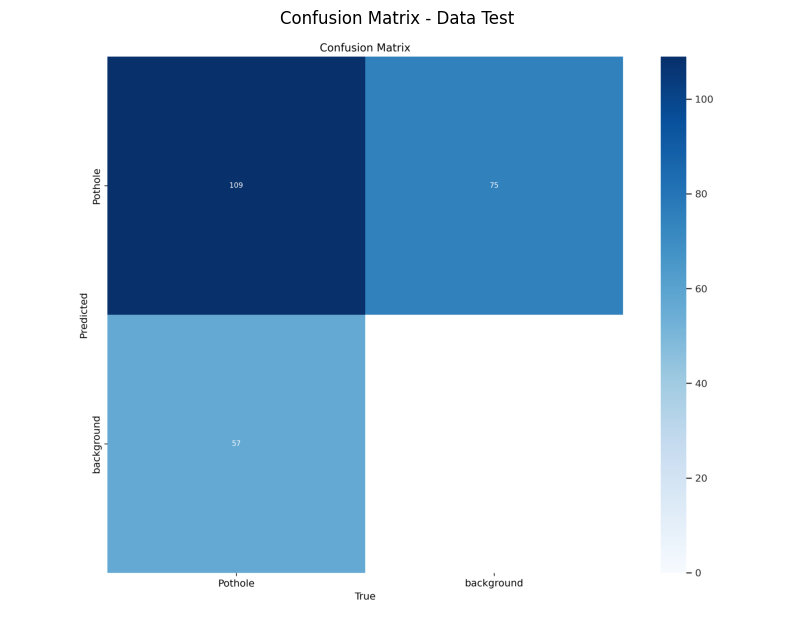

In [16]:
eval_test_dir = f'runs/detect/eval_test_{RUN_NAME}'

def show_eval_plot(directory, filename, title):
    path = os.path.join(directory, filename)
    if os.path.exists(path):
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(10, 8))
        plt.imshow(img)
        plt.title(title)
        plt.axis('off')
        plt.show()
    else:
        print(f"⚠️ File {filename} tidak ditemukan di {directory}. Pastikan model.val() sudah selesai.")

# Confusion matrix pada data uji
show_eval_plot(eval_test_dir, 'confusion_matrix.png', "Confusion Matrix - Data Test")

**Catatan.** Output notebook ini hilang (notebook tidak sengaja dimuat ulang), sehingga belum ada hasil yang dapat dibahas di sini. Bagian ini akan berisi insight setelah notebook dijalankan ulang.

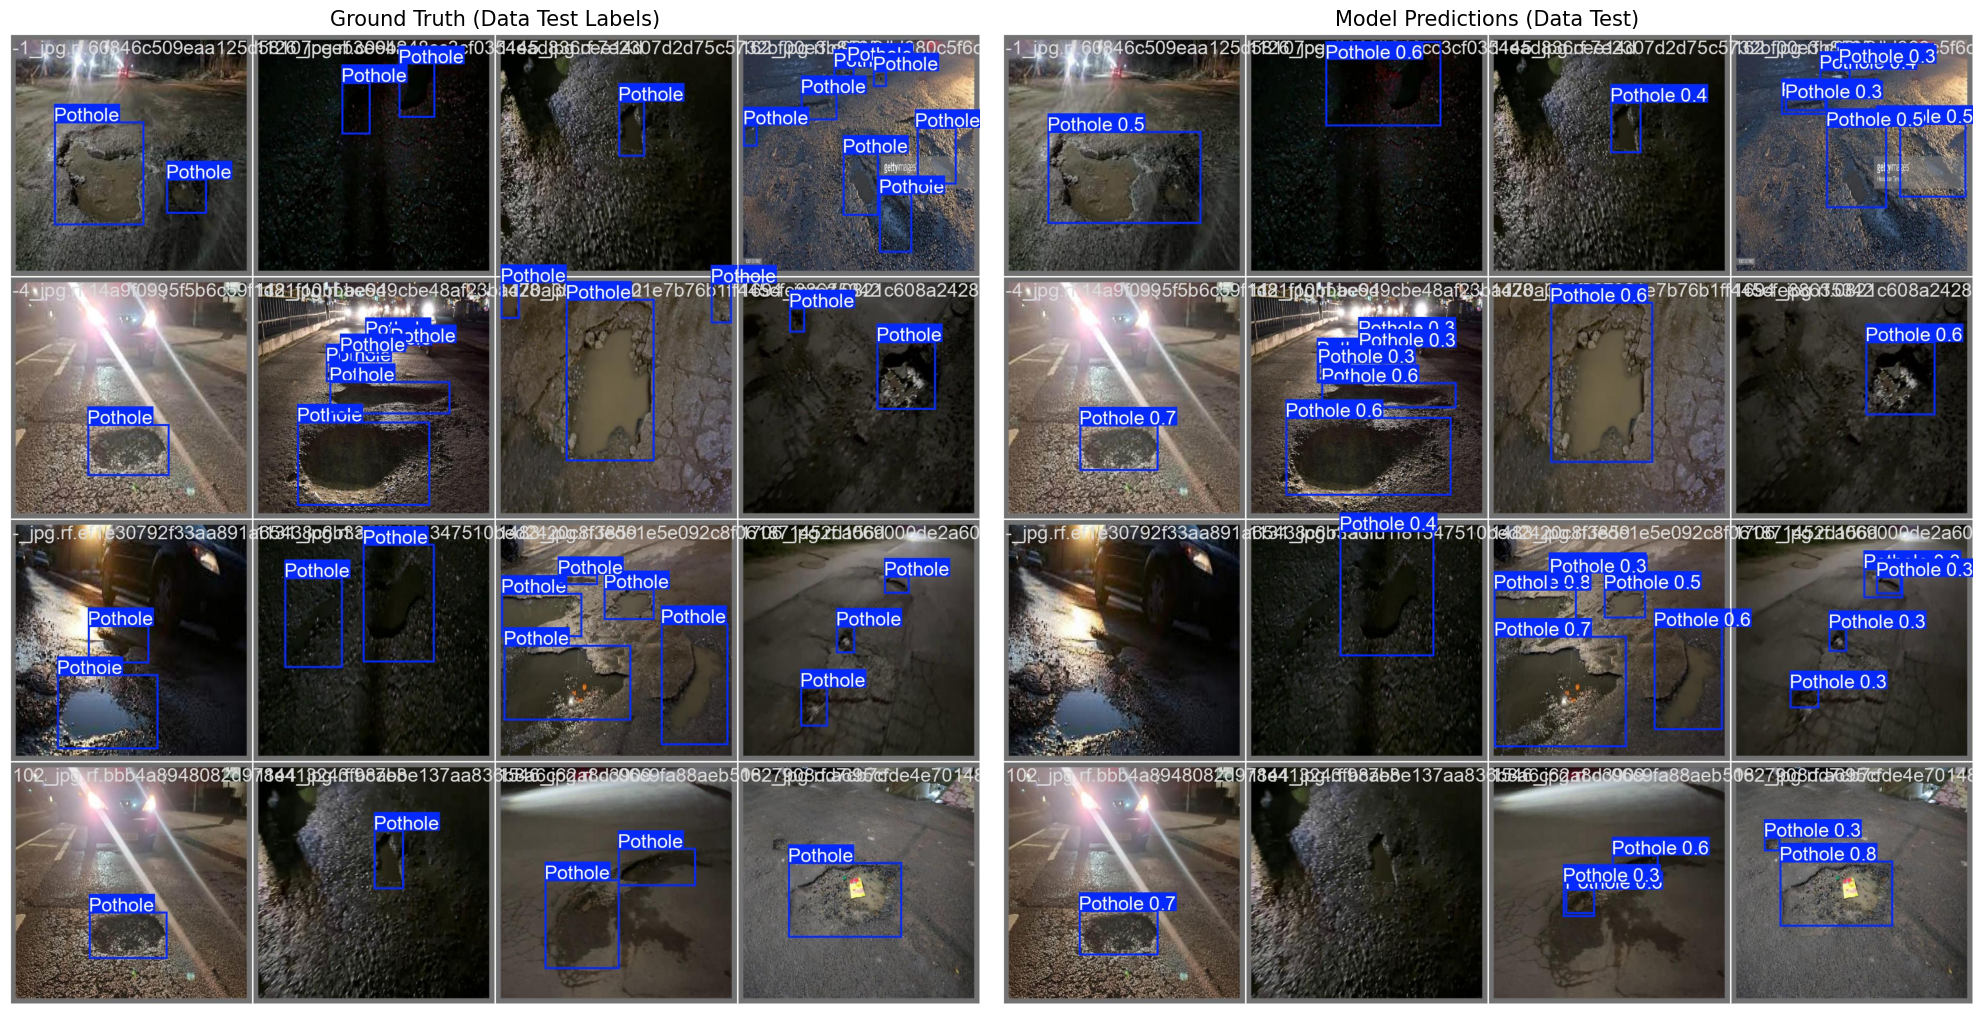

In [17]:
# Perbandingan label asli dan prediksi pada batch pertama data uji
# (Ultralytics tetap menamai file 'val_batch' walaupun split='test')
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

gt_path = os.path.join(eval_test_dir, 'val_batch0_labels.jpg')
if os.path.exists(gt_path):
    axes[0].imshow(cv2.cvtColor(cv2.imread(gt_path), cv2.COLOR_BGR2RGB))
    axes[0].set_title("Ground Truth (Data Test Labels)", fontsize=15)
    axes[0].axis('off')
else:
    print("⚠️ File label batch tidak ditemukan.")

pred_path = os.path.join(eval_test_dir, 'val_batch0_pred.jpg')
if os.path.exists(pred_path):
    axes[1].imshow(cv2.cvtColor(cv2.imread(pred_path), cv2.COLOR_BGR2RGB))
    axes[1].set_title("Model Predictions (Data Test)", fontsize=15)
    axes[1].axis('off')
else:
    print("⚠️ File prediksi batch tidak ditemukan.")

plt.tight_layout()
plt.show()

### Kurva pada data uji

Kurva PR, F1, Precision, dan Recall terhadap confidence pada data uji, serta confusion matrix ternormalisasi.

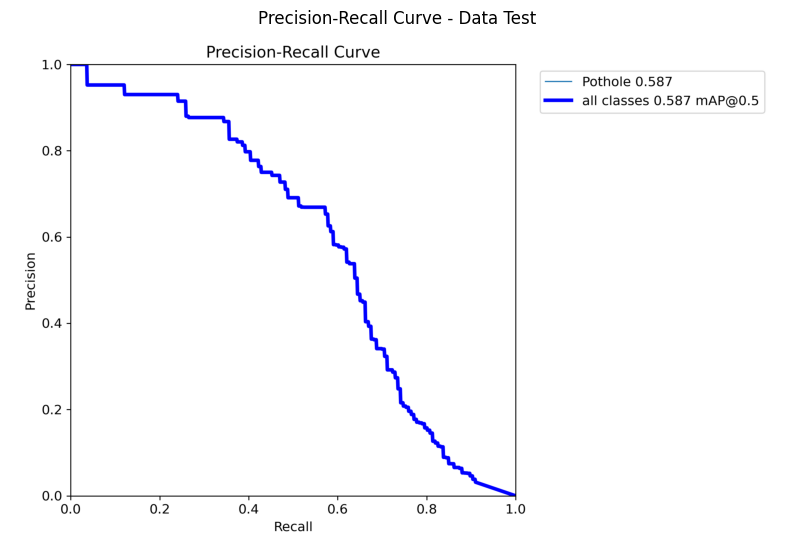

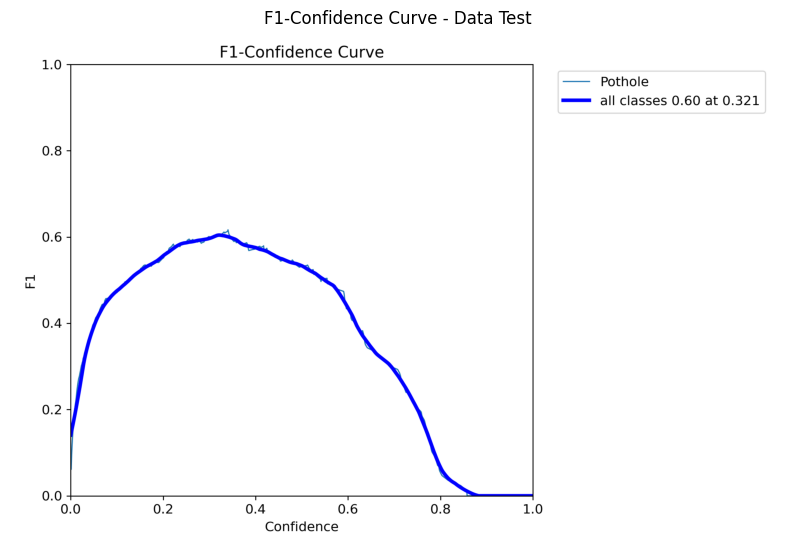

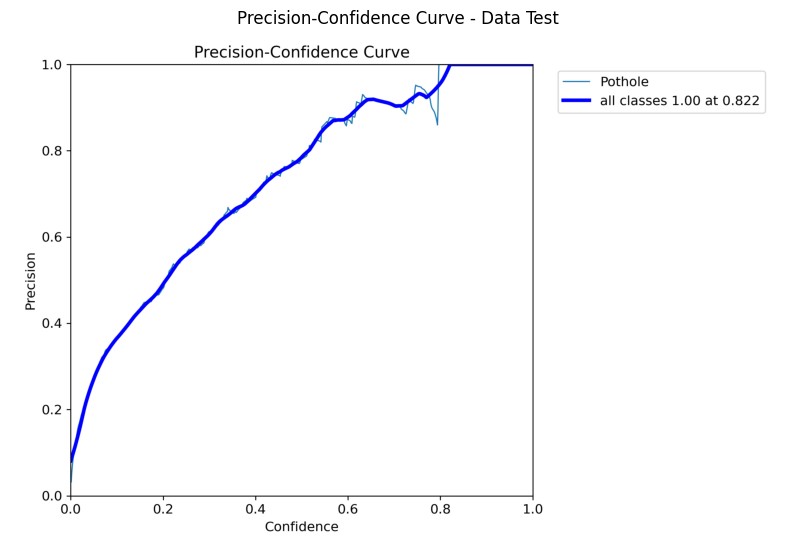

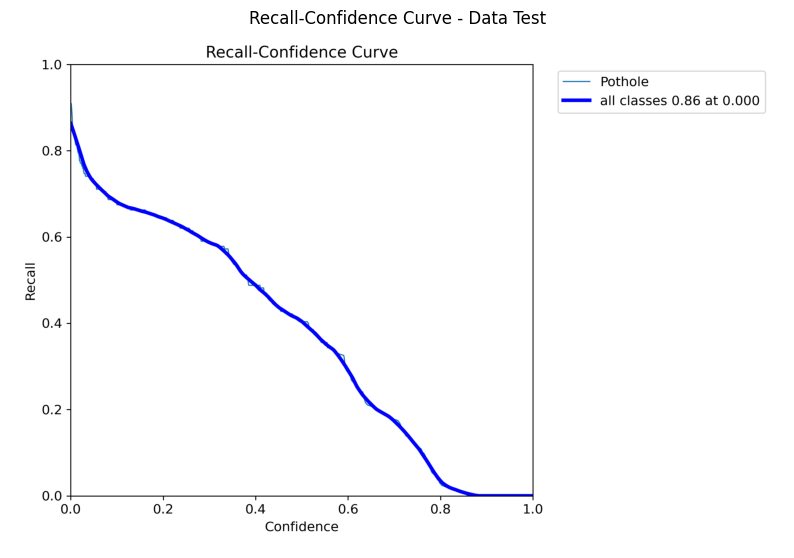

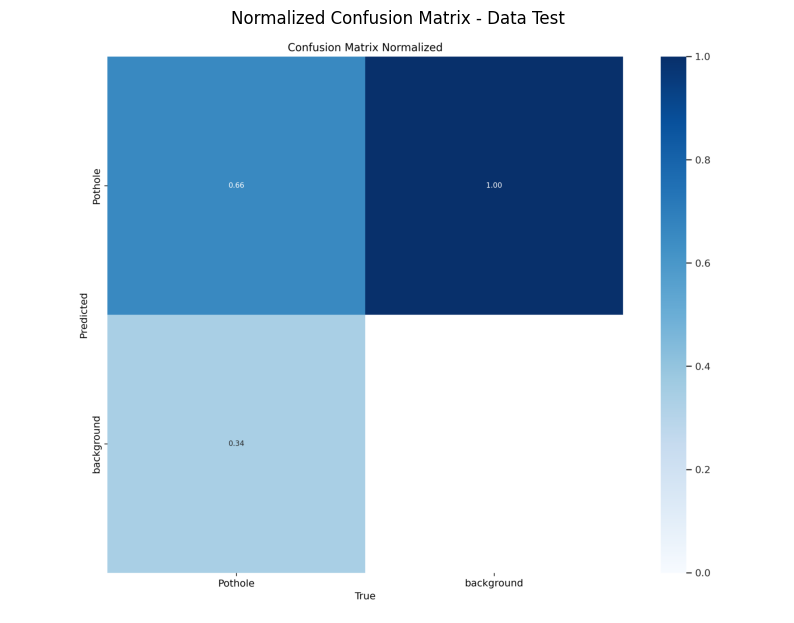

In [18]:
show_eval_plot(eval_test_dir, 'PR_curve.png', "Precision-Recall Curve - Data Test")
show_eval_plot(eval_test_dir, 'F1_curve.png', "F1-Confidence Curve - Data Test")
show_eval_plot(eval_test_dir, 'P_curve.png', "Precision-Confidence Curve - Data Test")
show_eval_plot(eval_test_dir, 'R_curve.png', "Recall-Confidence Curve - Data Test")
show_eval_plot(eval_test_dir, 'confusion_matrix_normalized.png', "Normalized Confusion Matrix - Data Test")

## 9. Ringkasan dan penyimpanan ke Google Drive

Sel pertama menyusun ringkasan metrik uji, jumlah parameter, kecepatan inferensi, dan versi lingkungan. Sel kedua menyimpan seluruh hasil ke Google Drive:

```
MyDrive/Output Yolo/<OUTPUT_GROUP>/<RUN_NAME>/
├── train/                  # folder hasil pelatihan (weights/best.pt, results.csv, kurva)
├── eval_test/              # folder hasil evaluasi pada data uji
└── summary_<RUN_NAME>.json # ringkasan metrik dan lingkungan
```

In [19]:
import json, sys
import torch, ultralytics

n_params = sum(p.numel() for p in model.model.parameters())
inf_ms = metrics.speed.get('inference', float('nan'))

summary = {
    "run": RUN_NAME,
    "model": MODEL_WEIGHTS.replace(".pt", ""),
    "scenario": SCENARIO,
    "dataset": DATASET_SLUG,
    "best_epoch": best_epoch,
    "params": int(n_params),
    "inference_ms_per_image": round(float(inf_ms), 2),
    "test": {
        "precision": round(float(prec), 4),
        "recall": round(float(rec), 4),
        "map50": round(float(map50), 4),
        "map50_95": round(float(map95), 4),
    },
    "environment": {
        "python": sys.version.split()[0],
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "ultralytics": ultralytics.__version__,
        "gpu": torch.cuda.get_device_name(0),
    },
}
print(json.dumps(summary, indent=2))

{
  "run": "yolov12n_sintetis100",
  "model": "yolov12n",
  "scenario": "Sintetis 100% (700 citra siang + 700 citra malam sintetis, augmentasi 3x)",
  "dataset": "pororozagi/aug-cycle",
  "best_epoch": 24,
  "params": 2508539,
  "inference_ms_per_image": 12.35,
  "test": {
    "precision": 0.6132,
    "recall": 0.5843,
    "map50": 0.5867,
    "map50_95": 0.2976
  },
  "environment": {
    "python": "3.13.15",
    "torch": "2.9.0+cu128",
    "cuda": "12.8",
    "ultralytics": "8.3.63",
    "gpu": "Tesla T4"
  }
}


In [20]:
import shutil
from google.colab import drive

drive.mount('/content/drive')
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Folder hasil pelatihan (berisi weights/best.pt dan last.pt)
shutil.copytree(f'runs/detect/{RUN_NAME}', os.path.join(OUTPUT_DIR, 'train'), dirs_exist_ok=True)

# 2. Folder hasil evaluasi data uji
shutil.copytree(eval_test_dir, os.path.join(OUTPUT_DIR, 'eval_test'), dirs_exist_ok=True)

# 3. Ringkasan metrik
with open(os.path.join(OUTPUT_DIR, f'summary_{RUN_NAME}.json'), 'w') as f:
    json.dump(summary, f, indent=2)

print(f"✅ Hasil tersimpan di: {OUTPUT_DIR}")
for root, dirs, files_ in os.walk(OUTPUT_DIR):
    depth = root[len(OUTPUT_DIR):].count(os.sep)
    if depth <= 1:
        print("  " * depth + os.path.basename(root) + "/")

Mounted at /content/drive
✅ Hasil tersimpan di: /content/drive/MyDrive/Output Yolo/100 Sintetis/yolov12n_sintetis100
yolov12n_sintetis100/
  train/
  eval_test/
